# Taylor Rule Tracker: Fed vs ECB

**Research question:** how do the Federal Reserve and the European Central Bank set interest rates, how far is today's policy from what a Taylor rule prescribes, and what does the market expect next?

The notebook is organised in seven steps:

1. **Data**: policy rates, core inflation, output gaps and 2-year yields for the US and the euro area
2. **The original Taylor rule** (1993): what the textbook rule prescribes vs what the central banks did
3. **Estimated reaction functions**: how strongly each central bank actually responds to inflation and to the output gap
4. **Policy tracker**: today's stance, restrictive or accommodative relative to each central bank's own rule
5. **Market pricing**: what 2-year yields imply for the policy path
6. **Scenarios**: the rule-implied rate under different inflation and growth outcomes
7. **Automatic export**: README, charts and tables generated and zipped, ready for GitHub

**How to use it:** set your GitHub username in the first code cell, then *Runtime → Run all*. At the end a zip file with everything for GitHub is downloaded automatically.

> Research and educational project. Not investment advice.

In [1]:
# ============================================================================
# SETTINGS: change these before running
# ============================================================================
AUTHOR = "Mattia Mariani"
GITHUB_USERNAME = "YOUR-USERNAME"
REPO_NAME = "taylor-rule-tracker"
NOTEBOOK_NAME = "taylor_rule_tracker.ipynb"

In [2]:
import io
import os
import shutil
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.filters.hp_filter import hpfilter

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# --- Model parameters -------------------------------------------------------
INFLATION_TARGET = 2.0   # both the Fed and the ECB target 2% inflation
R_STAR_TAYLOR = 2.0      # neutral real rate in Taylor (1993)
R_STAR_LOW = 0.5         # lower neutral rate, closer to post-2008 estimates
LOWER_BOUND = 0.25       # below this, policy is treated as constrained by the lower bound

PRE_CRISIS = {"Fed": ("1987Q3", "2008Q3"), "ECB": ("1999Q1", "2008Q3")}
FULL_START = {"Fed": "1987Q3", "ECB": "1999Q1"}

COLORS = {"Fed": "#1f4e79", "ECB": "#c47f00"}
BANKS = ["Fed", "ECB"]

# --- Output folders (everything inside OUT is what goes on GitHub) ----------
OUT = "github_export"
FIG = f"{OUT}/figures"
TAB = f"{OUT}/tables"
for d in (FIG, TAB):
    os.makedirs(d, exist_ok=True)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}", dpi=150, bbox_inches="tight")

## Step 1: Data

| Variable | United States (FRED) | Euro area (ECB Data Portal) |
|---|---|---|
| Policy rate | Effective Fed Funds rate | Overnight rate: EONIA until Sep 2019, €STR afterwards |
| Inflation | Core PCE, year-on-year (the Fed's preferred measure) | Core HICP (excl. energy and food), year-on-year |
| Output gap | Real GDP vs CBO potential GDP | Real GDP vs Hodrick-Prescott trend |
| Market expectations | 2-year Treasury yield | 2-year AAA euro-area government yield |

**Why core inflation?** It excludes energy and food, whose prices are volatile and largely outside the central bank's control. Central banks look through these swings.

**Why two different output-gap measures?** The output gap (how far the economy is above or below its potential) is not observable and has to be estimated. For the US there is an official estimate from the Congressional Budget Office (CBO). For the euro area there is no free equivalent, so the gap is estimated with a Hodrick-Prescott (HP) filter, a standard statistical method that separates the trend from the cycle.

All data are quarterly averages. Everything is downloaded automatically and no API key is needed.

In [3]:
def fred(series_id):
    # Download a FRED series as a pandas Series (no API key needed)
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    return df.iloc[:, 0].astype(float).dropna()


def _parse_dates(periods):
    periods = periods.astype(str)
    if periods.str.contains("-Q").any():                           # quarterly, e.g. 2025-Q1
        return pd.PeriodIndex(periods.str.replace("-Q", "Q"), freq="Q").to_timestamp()
    return pd.to_datetime(periods)                                 # monthly or daily


def ecb(*keys):
    # Download a series from the ECB Data Portal. Several keys can be given:
    # the first one that works is used (the ECB occasionally renames datasets).
    errors = []
    for key in keys:
        flow, series = key.split("/", 1)
        url = f"https://data-api.ecb.europa.eu/service/data/{flow}/{series}"
        try:
            r = requests.get(url, params={"format": "csvdata"}, timeout=60)
            r.raise_for_status()
            df = pd.read_csv(io.StringIO(r.text))
            s = pd.Series(pd.to_numeric(df["OBS_VALUE"], errors="coerce").values,
                          index=_parse_dates(df["TIME_PERIOD"]))
            return s.dropna().sort_index()
        except Exception as e:
            errors.append(f"  {key}: {e}")
    raise RuntimeError("ECB download failed for all keys:\n" + "\n".join(errors))


def quarterly(s):
    # Average of the quarter, indexed by quarter (e.g. 2025Q1)
    return s.resample("QS").mean().to_period("Q")


def step_series(s):
    # Series recorded only on the dates it changes (e.g. ECB key rates) -> daily, carried forward
    return s.resample("D").last().ffill()

In [4]:
# ---------------------------------------------------------------- United States
us_infl_m = fred("PCEPILFE").pct_change(12, fill_method=None) * 100     # monthly core PCE yoy
us_rate_m = fred("FEDFUNDS")
us_2y_d = fred("DGS2")
us_gap_q = quarterly(100 * (fred("GDPC1") / fred("GDPPOT") - 1)).dropna()

us = pd.DataFrame({
    "policy_rate": quarterly(us_rate_m),
    "inflation": quarterly(us_infl_m),
    "output_gap": us_gap_q,
    "yield_2y": quarterly(us_2y_d),
})

# ---------------------------------------------------------------- Euro area
ea_infl_m = ecb("HICP/M.U2.N.XEF000.4D0.ANR", "ICP/M.U2.N.XEF000.4.ANR")   # core HICP yoy

# Overnight rate: EONIA until Sep 2019, then €STR (EONIA was discontinued at the end of 2021).
# If both fail, fall back to the deposit facility rate.
try:
    eonia = ecb("FM/M.U2.EUR.4F.MM.EONIA.HSTA")
    estr = ecb("FM/M.U2.EUR.4F.MM.UONSTR.HSTA")
    ea_rate_m = pd.concat([eonia[eonia.index < "2019-10-01"], estr[estr.index >= "2019-10-01"]])
    EA_RATE_LABEL = "EONIA / €STR"
except RuntimeError as e:
    print("Overnight rate not available, using the deposit facility rate instead.\n", e)
    ea_rate_m = step_series(ecb("FM/B.U2.EUR.4F.KR.DFR.LEV", "FM/D.U2.EUR.4F.KR.DFR.LEV")).resample("MS").mean()
    EA_RATE_LABEL = "Deposit facility rate"

ea_gdp = ecb("MNA/Q.Y.I9.W2.S1.S1.B.B1GQ._Z._Z._Z.EUR.LR.N", "MNA/Q.Y.I8.W2.S1.S1.B.B1GQ._Z._Z._Z.EUR.LR.N")
ea_cycle, _ = hpfilter(np.log(ea_gdp) * 100, lamb=1600)       # cycle in % of trend GDP
ea_2y_d = ecb("YC/B.U2.EUR.4F.G_N_A.SV_C_YM.SR_2Y")

ea = pd.DataFrame({
    "policy_rate": quarterly(ea_rate_m),
    "inflation": quarterly(ea_infl_m),
    "output_gap": quarterly(ea_cycle),
    "yield_2y": quarterly(ea_2y_d),
})

data = {"Fed": us.loc[FULL_START["Fed"]:], "ECB": ea.loc[FULL_START["ECB"]:]}
for bank, df in data.items():
    df["at_lower_bound"] = df["policy_rate"] < LOWER_BOUND
    complete = df.dropna(subset=["policy_rate", "inflation", "output_gap"])
    print(f"{bank}: {complete.index[0]} -> {complete.index[-1]} ({len(complete)} complete quarters)")

# Latest available values (monthly or daily data are more recent than GDP)
def last(s):
    s = s.dropna()
    return s.iloc[-1], s.index[-1]

latest = {
    "Fed": {"policy_rate": last(us_rate_m), "inflation": last(us_infl_m),
            "output_gap": last(us_gap_q), "yield_2y": last(us_2y_d)},
    "ECB": {"policy_rate": last(ea_rate_m), "inflation": last(ea_infl_m),
            "output_gap": last(quarterly(ea_cycle)), "yield_2y": last(ea_2y_d)},
}
data["ECB"].tail()

Fed: 1987Q3 -> 2026Q3 (157 complete quarters)
ECB: 1999Q1 -> 2026Q1 (109 complete quarters)


,policy_rate,inflation,output_gap,yield_2y,at_lower_bound
TIME_PERIOD,,,,,
2025Q4,1.93,2.37,-0.35,2.01,False
2026Q1,1.93,2.30,-0.71,2.17,False
2026Q2,1.97,2.40,NaN,2.56,False
2026Q3,2.23,2.47,NaN,2.83,False
2026Q4,2.44,2.60,NaN,3.03,False


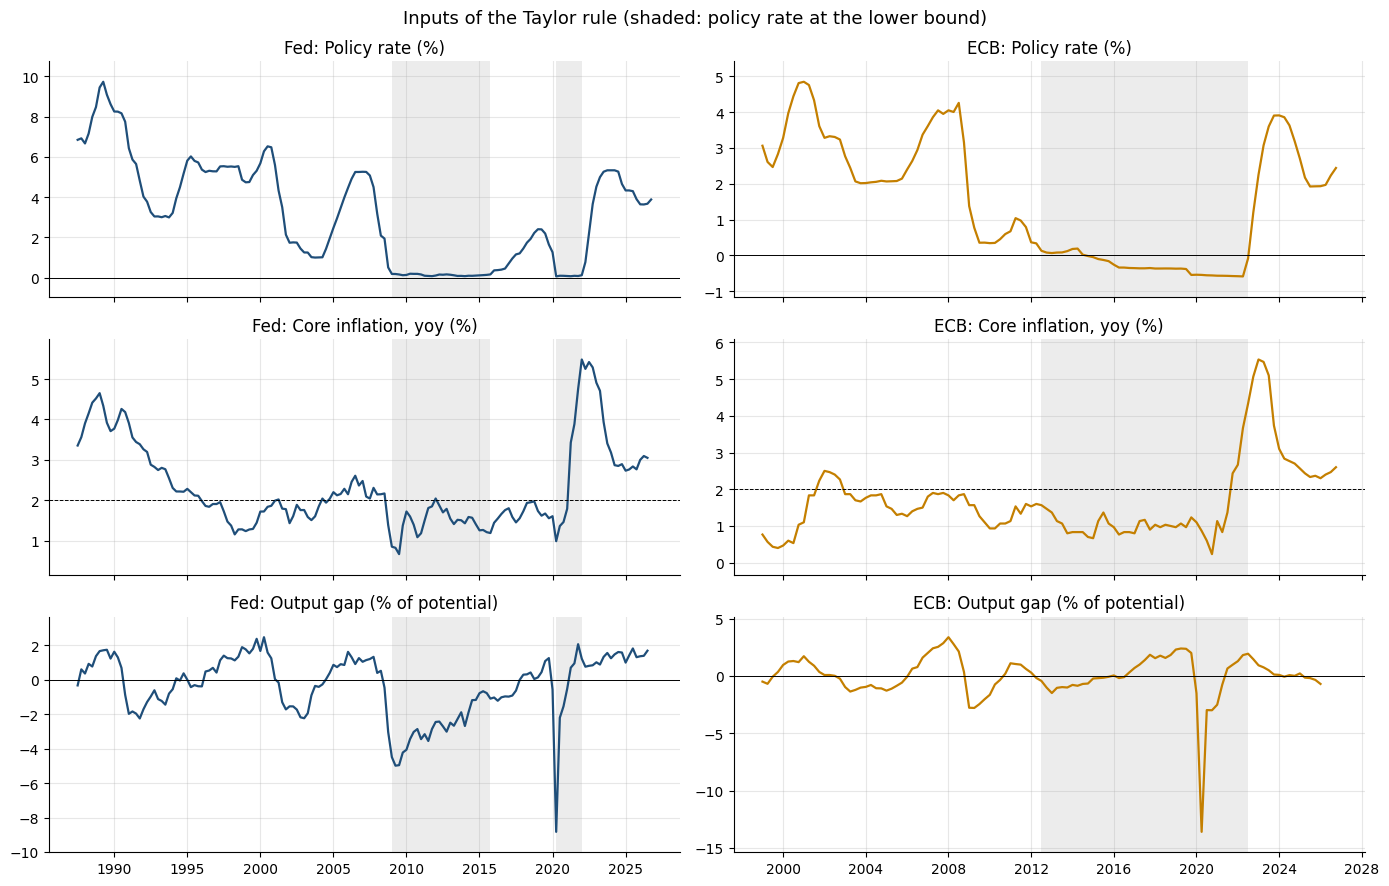

In [5]:
# Chart: the inputs of the rule
rows = [("policy_rate", "Policy rate (%)"), ("inflation", "Core inflation, yoy (%)"), ("output_gap", "Output gap (% of potential)")]
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex="col")
for j, bank in enumerate(BANKS):
    df = data[bank]
    t = df.index.to_timestamp()
    for i, (col, title) in enumerate(rows):
        ax = axes[i, j]
        ax.plot(t, df[col], color=COLORS[bank], lw=1.6)
        ax.axhline(INFLATION_TARGET if col == "inflation" else 0, color="black", lw=0.7, ls="--" if col == "inflation" else "-")
        ax.fill_between(t, 0, 1, where=df["at_lower_bound"], color="grey", alpha=0.15,
                        transform=ax.get_xaxis_transform(), lw=0)
        ax.set_title(f"{bank}: {title}")
fig.suptitle("Inputs of the Taylor rule (shaded: policy rate at the lower bound)", fontsize=13)
fig.tight_layout()
save(fig, "01_inputs.png")
plt.show()

## Step 2: The original Taylor rule

In 1993 John Taylor showed that Fed policy could be described by a simple formula:

$$i = r^* + \pi + 0.5\,(\pi - \pi^*) + 0.5\,\text{gap}$$

- $i$ is the policy rate the rule prescribes;
- $r^*$ is the **neutral real rate**, the real rate that neither stimulates nor restrains the economy (2% in the original);
- $\pi$ is inflation and $\pi^*$ the 2% target;
- *gap* is the output gap.

The intuition: when inflation is 1 point above target, the nominal rate rises by **1.5 points**, so the *real* rate rises too and cools the economy. This is the **Taylor principle**: the response to inflation must be greater than one.

Many economists think the neutral rate has fallen since 2008, so the rule is also shown with $r^* = 0.5\%$. The gap between the two lines shows how uncertain this key parameter is.

When the rule falls below zero, it means the central bank would have wanted negative rates: this is why the Fed and the ECB turned to quantitative easing.

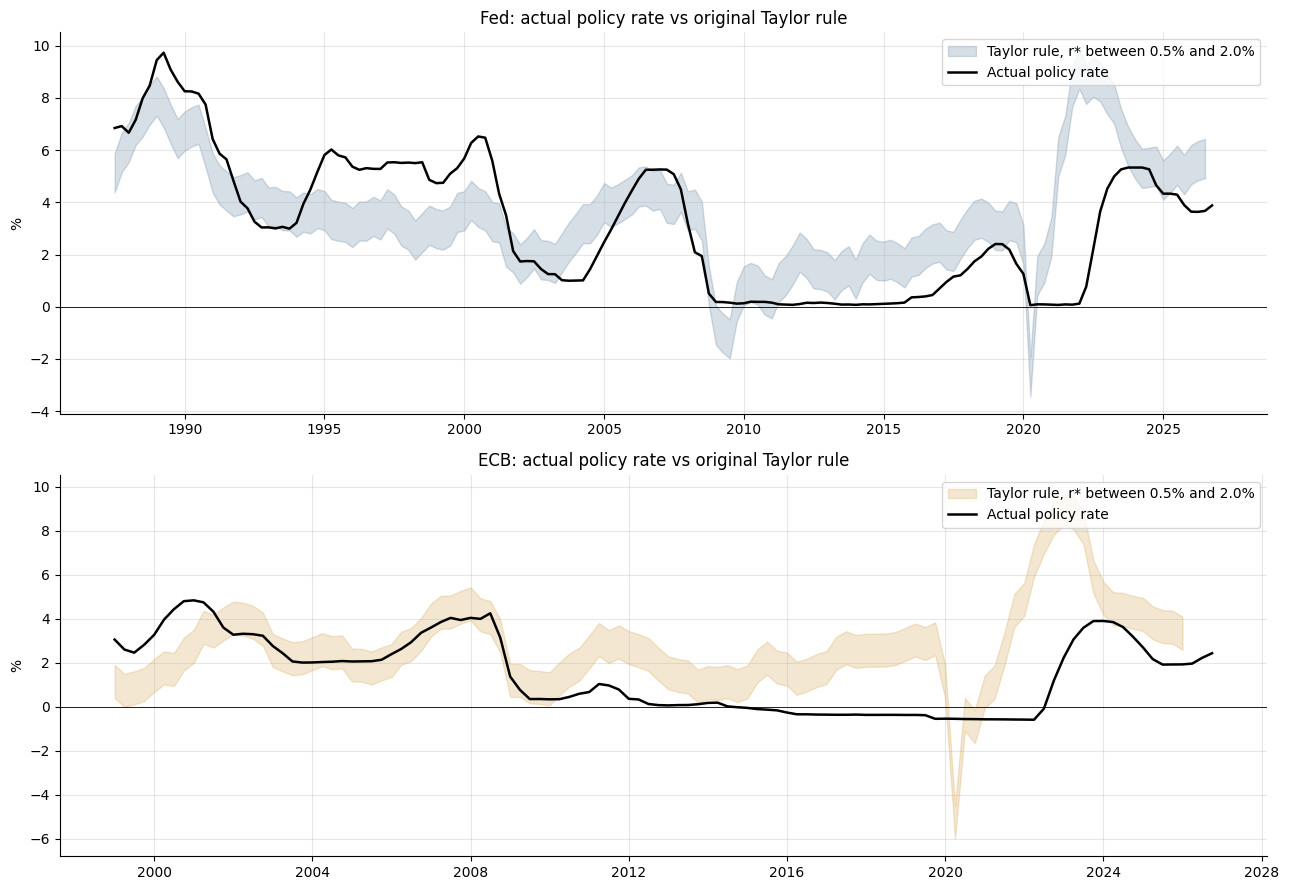

Average gap between actual rate and Taylor (1993) rule, percentage points
(negative = policy looser than the rule)


,Fed,ECB
2003-2005 ('too low for too long'),-1.90,-0.83
"2009-2015 (lower bound, QE)",-1.68,-2.11
2021Q2-2022Q2 ('behind the curve'),-8.19,-5.26
Last 4 quarters,-2.48,-2.37


In [6]:
def taylor_1993(df, r_star):
    return r_star + df["inflation"] + 0.5 * (df["inflation"] - INFLATION_TARGET) + 0.5 * df["output_gap"]


for bank, df in data.items():
    df["taylor_1993"] = taylor_1993(df, R_STAR_TAYLOR)
    df["taylor_low_rstar"] = taylor_1993(df, R_STAR_LOW)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for ax, bank in zip(axes, BANKS):
    df = data[bank]
    t = df.index.to_timestamp()
    ax.fill_between(t, df["taylor_low_rstar"], df["taylor_1993"], color=COLORS[bank], alpha=0.18,
                    label=f"Taylor rule, r* between {R_STAR_LOW}% and {R_STAR_TAYLOR}%")
    ax.plot(t, df["policy_rate"], color="black", lw=1.8, label="Actual policy rate")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{bank}: actual policy rate vs original Taylor rule")
    ax.set_ylabel("%")
    ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "02_original_taylor_rule.png")
plt.show()

# Average deviation from the original rule in well-known episodes
EPISODES = {
    "2003-2005 ('too low for too long')": ("2003Q1", "2005Q4"),
    "2009-2015 (lower bound, QE)": ("2009Q1", "2015Q4"),
    "2021Q2-2022Q2 ('behind the curve')": ("2021Q2", "2022Q2"),
    "Last 4 quarters": (None, None),
}
episodes = {}
for bank, df in data.items():
    dev = (df["policy_rate"] - df["taylor_1993"]).dropna()
    row = {}
    for name, (a, b) in EPISODES.items():
        part = dev.iloc[-4:] if a is None else dev.loc[a:b]
        row[name] = part.mean() if len(part) else np.nan
    episodes[bank] = row
episodes = pd.DataFrame(episodes)
episodes.to_csv(f"{TAB}/episodes_vs_taylor_1993.csv")
print("Average gap between actual rate and Taylor (1993) rule, percentage points")
print("(negative = policy looser than the rule)")
display(episodes)

## Step 3: Estimated reaction functions

The original rule imposes Taylor's coefficients. Here we **estimate** how each central bank actually behaved:

$$i_t = \rho\, i_{t-1} + (1-\rho)\,(\alpha + \beta_\pi \pi_t + \beta_y\, \text{gap}_t) + \varepsilon_t$$

- $\beta_\pi$ is the **long-run response to inflation**. If it is above 1, the Taylor principle holds.
- $\beta_y$ is the **long-run response to the output gap**. The Fed has a dual mandate (prices and employment), the ECB a primary mandate on prices, so we would expect a larger $\beta_y$ for the Fed.
- $\rho$ is **interest-rate smoothing**: central banks move gradually, so only a fraction $(1-\rho)$ of the distance to the target rate is closed each quarter.

The equation is estimated by OLS in the linear form $i_t = c + \rho\, i_{t-1} + b_\pi \pi_t + b_y \text{gap}_t$, and the long-run coefficients are recovered as $\beta = b/(1-\rho)$. Their standard errors use the **delta method**, and all standard errors are robust to autocorrelation (HAC). From the constant we can also back out the **implied neutral real rate** $r^* = \alpha + (\beta_\pi - 1)\,\pi^*$.

**Two samples:**
- **Pre-crisis** (Fed 1987-2008, i.e. Greenspan and early Bernanke; ECB 1999-2008): "normal" times, with no lower bound;
- **Full sample**, excluding the quarters at the lower bound, where the rate could not follow the rule.

In [7]:
def estimate(df, start, end=None):
    d = df[["policy_rate", "inflation", "output_gap"]].copy()
    d["lag_rate"] = d["policy_rate"].shift(1)
    d = d.loc[start:end].dropna()
    d = d[(d["policy_rate"] >= LOWER_BOUND) & (d["lag_rate"] >= LOWER_BOUND)]     # exclude lower bound
    X = sm.add_constant(d[["lag_rate", "inflation", "output_gap"]])
    m = sm.OLS(d["policy_rate"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    b, V = m.params, m.cov_params()
    rho = b["lag_rate"]

    def long_run(grad):
        g = pd.Series(grad).reindex(b.index).fillna(0.0)
        return float(np.sqrt(g @ V @ g))

    out = {"quarters": int(m.nobs), "rho": rho, "rho_se": m.bse["lag_rate"], "r2": m.rsquared}
    for name, label in [("const", "alpha"), ("inflation", "beta_pi"), ("output_gap", "beta_y")]:
        out[label] = b[name] / (1 - rho)
        out[label + "_se"] = long_run({name: 1 / (1 - rho), "lag_rate": b[name] / (1 - rho) ** 2})
    # Implied neutral real rate: r* = alpha + (beta_pi - 1) * pi*
    out["r_star"] = out["alpha"] + (out["beta_pi"] - 1) * INFLATION_TARGET
    out["r_star_se"] = long_run({"const": 1 / (1 - rho), "inflation": INFLATION_TARGET / (1 - rho),
                                 "lag_rate": (b["const"] + INFLATION_TARGET * b["inflation"]) / (1 - rho) ** 2})
    # One-sided test of the Taylor principle, H0: beta_pi <= 1
    out["taylor_t"] = (out["beta_pi"] - 1) / out["beta_pi_se"]
    out["taylor_p"] = 1 - stats.norm.cdf(out["taylor_t"])
    return out


results = {}
for bank in BANKS:
    results[(bank, "Pre-crisis")] = estimate(data[bank], *PRE_CRISIS[bank])
    results[(bank, "Full sample")] = estimate(data[bank], FULL_START[bank])
coef = pd.DataFrame(results).T
coef.index.names = ["bank", "sample"]
coef.to_csv(f"{TAB}/estimated_reaction_functions.csv")

for key, r in results.items():
    if r["rho"] > 0.95:
        print(f"WARNING {key}: smoothing parameter rho = {r['rho']:.2f} is close to 1, "
              "so long-run coefficients are imprecise.")

show = coef[["quarters", "rho", "beta_pi", "beta_pi_se", "beta_y", "beta_y_se", "r_star", "taylor_p", "r2"]]
display(show)

quarters  rho  beta_pi  beta_pi_se  beta_y  beta_y_se  \
bank sample                                                               
Fed  Pre-crisis      84.00 0.83     1.57        0.31    1.79       0.25   
     Full sample    118.00 0.87     1.64        0.37    1.71       0.29   
ECB  Pre-crisis      38.00 0.78    -0.79        0.70    0.86       0.18   
     Full sample     66.00 0.85     0.58        0.52    1.38       0.42   

                  r_star  taylor_p   r2  
bank sample                              
Fed  Pre-crisis     1.38      0.03 0.97  
     Full sample    0.76      0.04 0.97  
ECB  Pre-crisis     0.54      0.99 0.95  
     Full sample    0.30      0.79 0.94

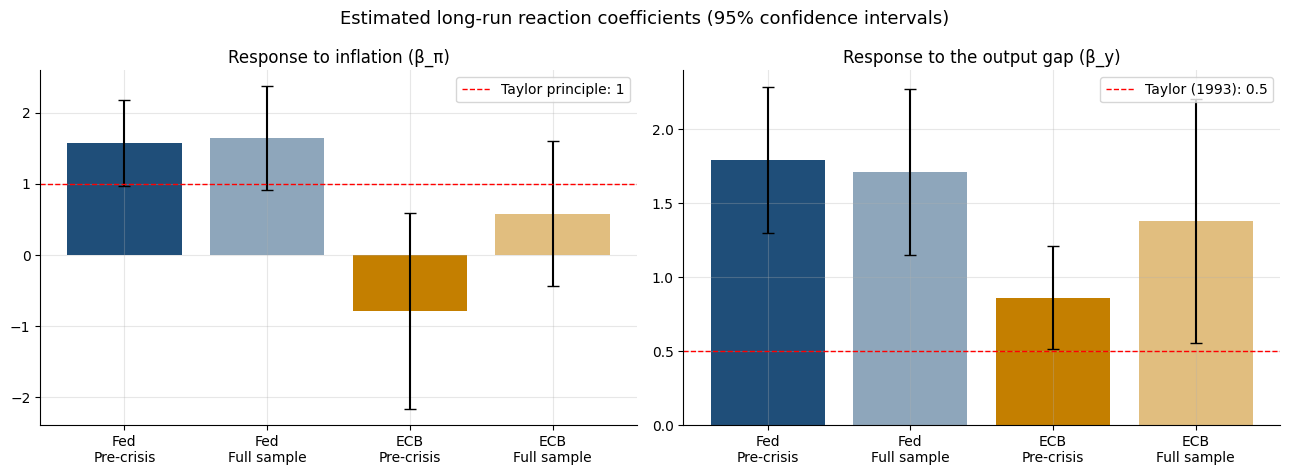

In [8]:
# Chart: long-run coefficients with 95% confidence intervals
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (param, title, ref) in zip(axes, [("beta_pi", "Response to inflation (β_π)", 1.0),
                                          ("beta_y", "Response to the output gap (β_y)", 0.5)]):
    labels, x = [], 0
    for bank in BANKS:
        for sample, alpha in [("Pre-crisis", 1.0), ("Full sample", 0.5)]:
            r = results[(bank, sample)]
            ax.bar(x, r[param], color=COLORS[bank], alpha=alpha)
            ax.errorbar(x, r[param], yerr=1.96 * r[param + "_se"], color="black", capsize=4)
            labels.append(f"{bank}\n{sample}")
            x += 1
    ax.axhline(ref, color="red", ls="--", lw=1, label=f"Taylor (1993): {ref}" if param == "beta_y" else "Taylor principle: 1")
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(title)
    ax.legend(loc="upper right")
fig.suptitle("Estimated long-run reaction coefficients (95% confidence intervals)", fontsize=13)
fig.tight_layout()
save(fig, "03_estimated_coefficients.png")
plt.show()

## Step 4: Policy tracker

Using the **pre-crisis** reaction function of each central bank, we compute the rate it "should" set today if it behaved as it did in normal times:

$$i^{rule}_t = \alpha + \beta_\pi \pi_t + \beta_y\, \text{gap}_t$$

The **policy gap** is the actual rate minus the rule:
- **positive** → policy is **restrictive** relative to the bank's own historical behaviour;
- **negative** → policy is **accommodative**.

For today's reading we use the most recent data available: monthly inflation and policy rates are more up to date than the quarterly GDP-based output gap.

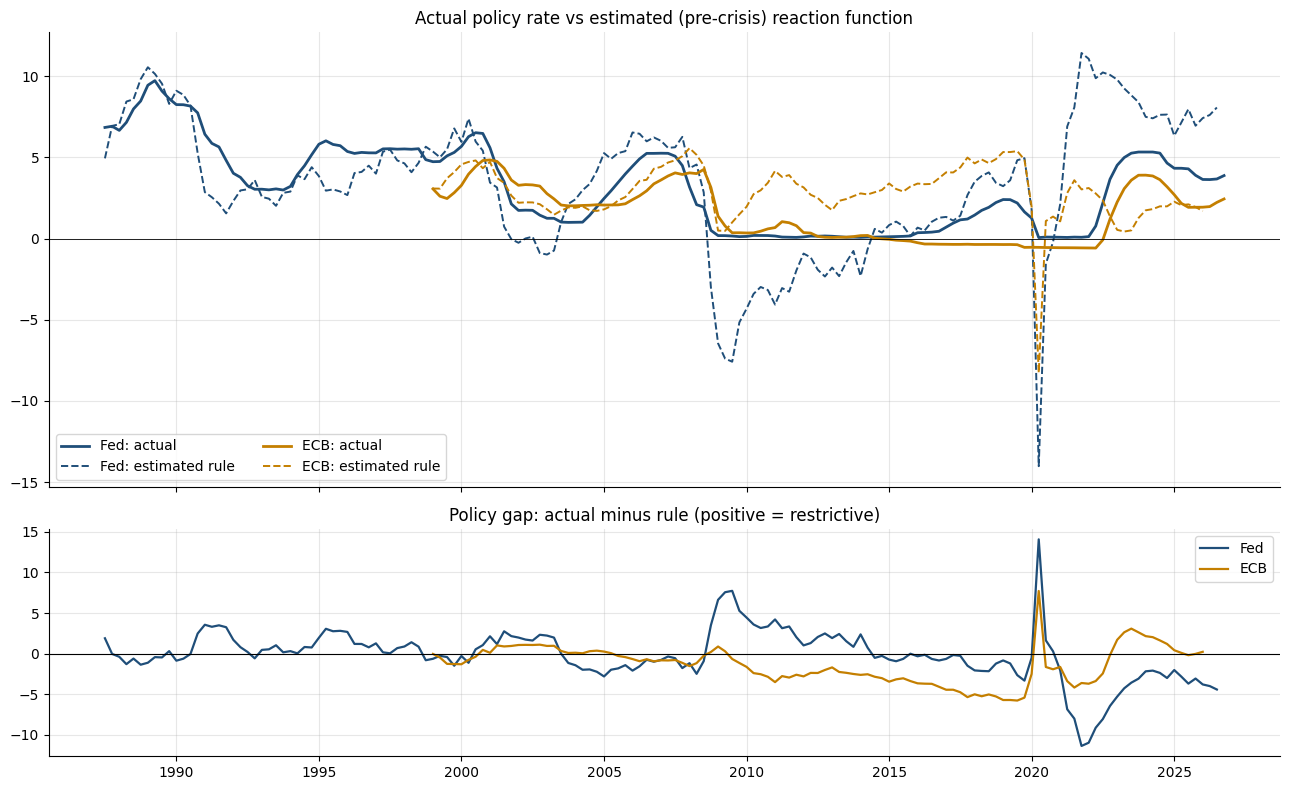

,Fed,ECB
Policy rate (%),3.88,2.44
Core inflation (%),3.12,2.60
Output gap (%),1.70,-0.71
"Taylor 1993, r*=2 (%)",6.53,4.55
"Taylor, r*=0.5 (%)",5.03,3.05
Estimated rule (%),8.18,1.46
Policy gap vs estimated rule (pp),-4.30,0.98
2-year yield (%),4.83,3.09
Stance,accommodative,restrictive
Data as of,"rate Oct 2026, inflation Sep 2026, gap 2026Q3,...","rate Oct 2026, inflation Oct 2026, gap 2026Q1,..."


In [9]:
def rule_rate(bank, inflation, gap):
    r = results[(bank, "Pre-crisis")]
    return r["alpha"] + r["beta_pi"] * inflation + r["beta_y"] * gap


for bank, df in data.items():
    df["estimated_rule"] = rule_rate(bank, df["inflation"], df["output_gap"])
    df["policy_gap"] = df["policy_rate"] - df["estimated_rule"]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for bank in BANKS:
    df = data[bank]
    t = df.index.to_timestamp()
    axes[0].plot(t, df["policy_rate"], color=COLORS[bank], lw=2, label=f"{bank}: actual")
    axes[0].plot(t, df["estimated_rule"], color=COLORS[bank], lw=1.4, ls="--", label=f"{bank}: estimated rule")
    axes[1].plot(t, df["policy_gap"], color=COLORS[bank], lw=1.6, label=bank)
axes[0].axhline(0, color="black", lw=0.6)
axes[0].set_title("Actual policy rate vs estimated (pre-crisis) reaction function")
axes[0].legend(ncol=2)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Policy gap: actual minus rule (positive = restrictive)")
axes[1].legend()
fig.tight_layout()
save(fig, "04_policy_tracker.png")
plt.show()

# --- Today's stance -------------------------------------------------------------
def stance_label(gap):
    if gap > 0.5:
        return "restrictive"
    if gap < -0.5:
        return "accommodative"
    return "broadly neutral"


stance = {}
for bank in BANKS:
    L = latest[bank]
    infl, gap, rate = L["inflation"][0], L["output_gap"][0], L["policy_rate"][0]
    est = rule_rate(bank, infl, gap)
    row = {
        "Policy rate (%)": rate,
        "Core inflation (%)": infl,
        "Output gap (%)": gap,
        "Taylor 1993, r*=2 (%)": taylor_1993(pd.DataFrame({"inflation": [infl], "output_gap": [gap]}), R_STAR_TAYLOR)[0],
        f"Taylor, r*={R_STAR_LOW} (%)": taylor_1993(pd.DataFrame({"inflation": [infl], "output_gap": [gap]}), R_STAR_LOW)[0],
        "Estimated rule (%)": est,
        "Policy gap vs estimated rule (pp)": rate - est,
        "2-year yield (%)": L["yield_2y"][0],
    }
    row["Stance"] = stance_label(row["Policy gap vs estimated rule (pp)"])
    row["Data as of"] = (f"rate {L['policy_rate'][1]:%b %Y}, inflation {L['inflation'][1]:%b %Y}, "
                         f"gap {L['output_gap'][1]}, 2y {L['yield_2y'][1]:%d %b %Y}")
    stance[bank] = row
stance = pd.DataFrame(stance)
stance.to_csv(f"{TAB}/current_stance.csv")
display(stance)

## Step 5: Market pricing

The **2-year government yield** is roughly the average policy rate the market expects over the next two years, plus a small term premium. Comparing it with today's policy rate gives a simple reading of market expectations:

- 2-year yield **below** the policy rate → the market expects **cuts**;
- 2-year yield **above** the policy rate → the market expects **hikes**.

This is the strategist's view: the **rule** says where rates *should* go, the **market** says where it *thinks* they will go. When the two disagree there is a potential trade, or a risk.

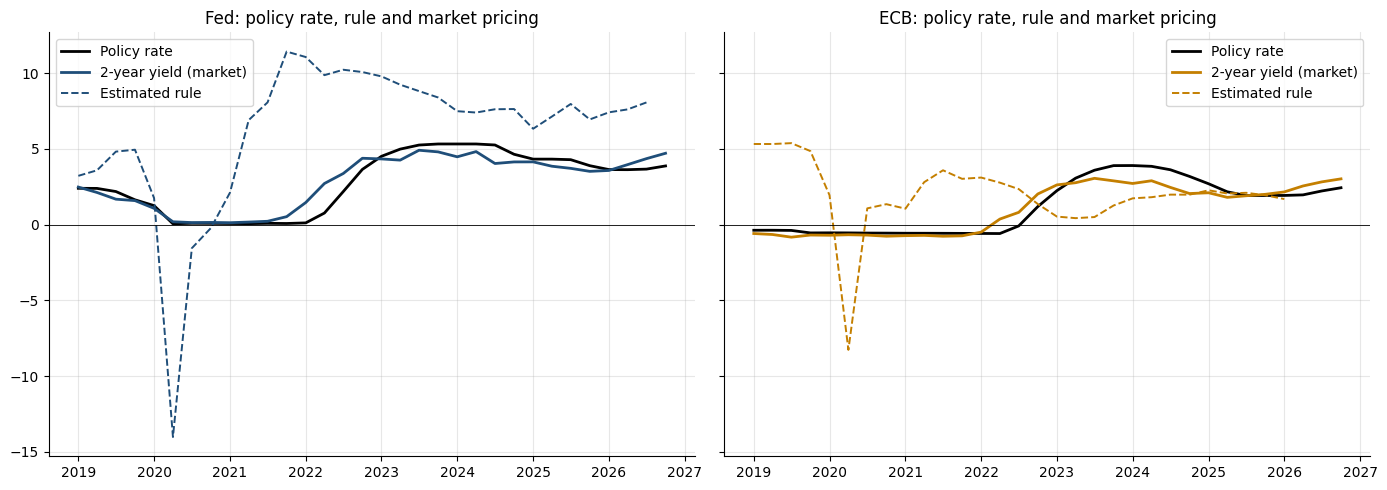

,Fed,ECB
2y yield minus policy rate (pp),0.95,0.65
Market is pricing,hikes,hikes
Rule minus policy rate (pp),4.30,-0.98


In [10]:
def market_label(spread):
    if spread < -0.25:
        return "cuts"
    if spread > 0.25:
        return "hikes"
    return "rates broadly on hold"


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, bank in zip(axes, BANKS):
    df = data[bank].loc["2019Q1":]
    t = df.index.to_timestamp()
    ax.plot(t, df["policy_rate"], color="black", lw=2, label="Policy rate")
    ax.plot(t, df["yield_2y"], color=COLORS[bank], lw=2, label="2-year yield (market)")
    ax.plot(t, df["estimated_rule"], color=COLORS[bank], lw=1.4, ls="--", label="Estimated rule")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{bank}: policy rate, rule and market pricing")
    ax.legend()
fig.tight_layout()
save(fig, "05_market_pricing.png")
plt.show()

market = {}
for bank in BANKS:
    rate, y2 = stance.loc["Policy rate (%)", bank], stance.loc["2-year yield (%)", bank]
    market[bank] = {"2y yield minus policy rate (pp)": y2 - rate, "Market is pricing": market_label(y2 - rate),
                    "Rule minus policy rate (pp)": stance.loc["Estimated rule (%)", bank] - rate}
market = pd.DataFrame(market)
market.to_csv(f"{TAB}/market_pricing.csv")
display(market)

## Step 6: Scenarios

A macro strategist is often asked: *"if inflation surprises at X and growth at Y, where should rates be?"* The estimated reaction functions answer this directly. Each cell shows the rule-implied rate for a combination of core inflation and output gap.

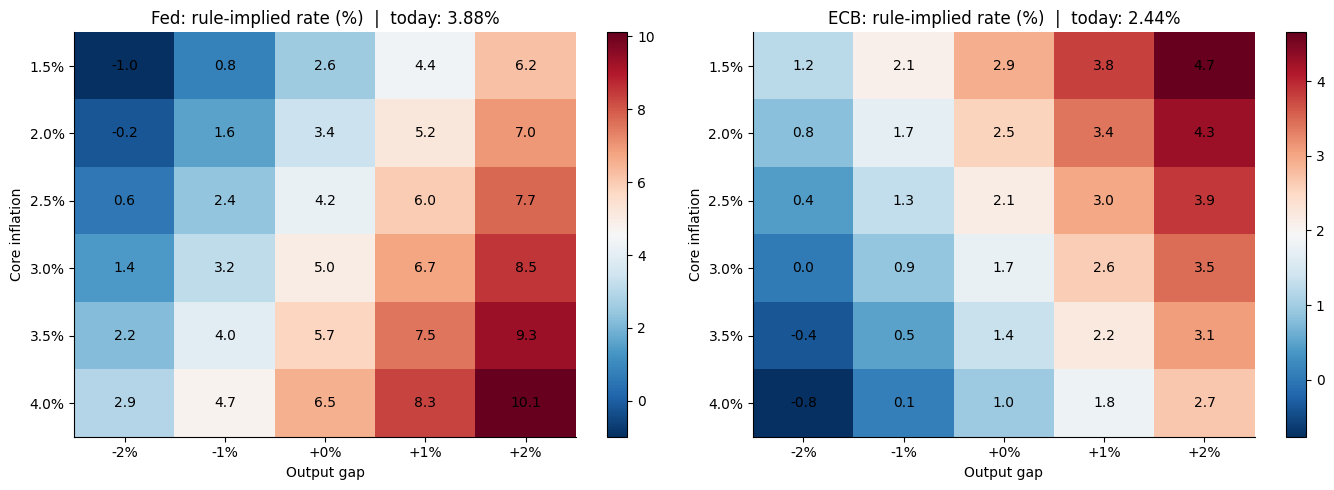

In [11]:
INFL_GRID = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
GAP_GRID = [-2.0, -1.0, 0.0, 1.0, 2.0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scenarios = {}
for ax, bank in zip(axes, BANKS):
    grid = pd.DataFrame([[rule_rate(bank, i, g) for g in GAP_GRID] for i in INFL_GRID],
                        index=[f"{i}%" for i in INFL_GRID], columns=[f"{g:+.0f}%" for g in GAP_GRID])
    grid.index.name, grid.columns.name = "Core inflation", "Output gap"
    scenarios[bank] = grid
    grid.to_csv(f"{TAB}/scenarios_{bank.lower()}.csv")
    im = ax.imshow(grid.values, cmap="RdBu_r", aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.iloc[i, j]:.1f}", ha="center", va="center", fontsize=10)
    ax.set_xticks(range(len(GAP_GRID)), grid.columns)
    ax.set_yticks(range(len(INFL_GRID)), grid.index)
    ax.set_xlabel("Output gap")
    ax.set_ylabel("Core inflation")
    ax.grid(False)
    ax.set_title(f"{bank}: rule-implied rate (%)  |  today: {stance.loc['Policy rate (%)', bank]:.2f}%")
    fig.colorbar(im, ax=ax)
fig.tight_layout()
save(fig, "06_scenarios.png")
plt.show()

## Step 7: Automatic export for GitHub

This cell writes a complete `README.md` with today's numbers and interpretation, adds `requirements.txt` and `.gitignore`, and zips everything together with the charts and tables. In Colab the zip is downloaded automatically.

**What to upload to GitHub:** unzip the file and upload its contents, plus this notebook (*File → Download → Download .ipynb*). Save the notebook **after** running it, so GitHub shows the charts and tables inside it.

In [12]:
TODAY = date.today().strftime("%d %B %Y")


def f2(x):
    return f"{x:.2f}"


def md_table(df, fmt=f2):
    cols = [str(c) for c in df.columns]
    lines = ["| | " + " | ".join(cols) + " |", "|---|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        cells = [fmt(v) if isinstance(v, (int, float, np.floating)) and not isinstance(v, bool) else str(v) for v in row]
        lines.append(f"| {idx} | " + " | ".join(cells) + " |")
    return "\n".join(lines)


def coef_text(bank):
    r = results[(bank, "Pre-crisis")]
    holds = r["beta_pi"] > 1 and r["taylor_p"] < 0.05
    text = (f"The {bank}'s long-run response to inflation is **{r['beta_pi']:.2f}** "
            f"(standard error {r['beta_pi_se']:.2f}), so ")
    if holds:
        text += "the **Taylor principle holds**: the real rate rises when inflation rises (significant at 5%). "
    elif r["beta_pi"] > 1:
        text += "the point estimate satisfies the Taylor principle, but it is **not statistically significant** at 5%. "
    else:
        text += "the **Taylor principle does not hold** in this sample: the real rate did not rise with inflation. "
    text += (f"The response to the output gap is {r['beta_y']:.2f}, smoothing is ρ = {r['rho']:.2f} "
             f"(about {100 * (1 - r['rho']):.0f}% of the distance to the target rate is closed each quarter), "
             f"and the implied neutral real rate is {r['r_star']:.2f}%.")
    return text


def compare_text():
    f, e = results[("Fed", "Pre-crisis")], results[("ECB", "Pre-crisis")]
    gap_word = "more" if f["beta_y"] > e["beta_y"] else "less"
    infl_word = "more" if f["beta_pi"] > e["beta_pi"] else "less"
    text = (f"Before 2008 the Fed responded **{gap_word}** strongly than the ECB to the output gap "
            f"({f['beta_y']:.2f} vs {e['beta_y']:.2f}) and **{infl_word}** strongly to inflation "
            f"({f['beta_pi']:.2f} vs {e['beta_pi']:.2f}). ")
    if f["beta_y"] > e["beta_y"]:
        text += "This is consistent with the Fed's dual mandate (price stability and maximum employment) versus the ECB's primary focus on price stability."
    else:
        text += "This goes against the usual expectation based on mandates (the Fed has a dual mandate, the ECB a primary price-stability mandate), and is worth investigating further."
    return text


def stance_text(bank):
    s, m = stance[bank], market[bank]
    gap = s["Policy gap vs estimated rule (pp)"]
    text = (f"**{bank}.** The policy rate is {s['Policy rate (%)']:.2f}% against an estimated-rule rate of "
            f"{s['Estimated rule (%)']:.2f}%, so policy is **{s['Stance']}** relative to the bank's pre-crisis behaviour "
            f"(gap {gap:+.2f} pp). The 2-year yield is {s['2-year yield (%)']:.2f}%, so the market is pricing **{m['Market is pricing']}**")
    rule_dir = m["Rule minus policy rate (pp)"]
    market_dir = m["2y yield minus policy rate (pp)"]
    rule_word = "hikes" if rule_dir > 0 else "cuts"
    if abs(rule_dir) <= 0.5:
        text += ", while the rule suggests the current level is about right."
    elif m["Market is pricing"] == "rates broadly on hold":
        text += f", while the rule points to **{rule_word}**: the market does not expect the bank to follow its historical behaviour."
    elif np.sign(rule_dir) != np.sign(market_dir):
        text += f", **in the opposite direction** to the rule, which points to {rule_word}: a divergence worth monitoring."
    else:
        text += ", in the same direction as the rule."
    return text


def episode_text():
    e = episodes
    parts = []
    k = "2003-2005 ('too low for too long')"
    if k in e.index and not np.isnan(e.loc[k, "Fed"]):
        parts.append(f"In 2003-2005 the Fed kept rates on average **{e.loc[k, 'Fed']:+.2f} pp** away from the original rule, "
                     "the episode John Taylor himself criticised as 'too low for too long' ahead of the housing bubble.")
    k = "2021Q2-2022Q2 ('behind the curve')"
    if k in e.index:
        parts.append(f"In the 2021-2022 inflation surge the gap was **{e.loc[k, 'Fed']:+.2f} pp** for the Fed and "
                     f"**{e.loc[k, 'ECB']:+.2f} pp** for the ECB: both central banks reacted late, as they judged inflation transitory.")
    return " ".join(parts)


fed_pc, ecb_pc = results[("Fed", "Pre-crisis")], results[("ECB", "Pre-crisis")]
summary = (f"Using a Taylor-rule framework on US and euro-area data, the Fed's estimated pre-crisis response to inflation is "
           f"{fed_pc['beta_pi']:.2f} and the ECB's is {ecb_pc['beta_pi']:.2f}. Today the Fed's stance is "
           f"**{stance.loc['Stance', 'Fed']}** and the ECB's is **{stance.loc['Stance', 'ECB']}** relative to their own "
           f"historical reaction functions, while markets are pricing **{market.loc['Market is pricing', 'Fed']}** in the US "
           f"and **{market.loc['Market is pricing', 'ECB']}** in the euro area.")

coef_md = coef[["quarters", "rho", "beta_pi", "beta_pi_se", "beta_y", "beta_y_se", "r_star", "taylor_p"]].copy()
coef_md.index = [f"{b}, {s}" for b, s in coef_md.index]
coef_md.columns = ["Quarters", "ρ", "β_π", "s.e.", "β_y", "s.e.", "Implied r* (%)", "p-value β_π ≤ 1"]
coef_md["Quarters"] = coef_md["Quarters"].astype(int).astype(str)

stance_md = stance.drop(index=["Data as of"])
coef_table = md_table(coef_md)
badge = (f"https://colab.research.google.com/github/{GITHUB_USERNAME}/{REPO_NAME}/blob/main/{NOTEBOOK_NAME}")

readme = f"""# Taylor Rule Tracker: Fed vs ECB

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)]({badge})

**Author:** {AUTHOR}
**Last updated:** {TODAY} (all numbers and charts are generated automatically by the notebook)

## Summary

{summary}

## Research question

How do the Federal Reserve and the European Central Bank set interest rates? How far is today's policy from what a Taylor rule prescribes, and is the market pricing the same direction?

## The Taylor rule

Taylor (1993) showed that US monetary policy could be described by

$$i = r^* + \\pi + 0.5(\\pi - \\pi^*) + 0.5\\,\\text{{gap}}$$

where $i$ is the policy rate, $r^*$ the neutral real rate, $\\pi$ inflation, $\\pi^*$ the 2% target and *gap* the output gap. The key implication is the **Taylor principle**: the policy rate must rise more than one-for-one with inflation, so that the real rate rises and cools demand.

## Data

| Variable | United States (FRED) | Euro area (ECB Data Portal) |
|---|---|---|
| Policy rate | Effective Fed Funds rate | {EA_RATE_LABEL} |
| Inflation | Core PCE, yoy | Core HICP (excl. energy and food), yoy |
| Output gap | Real GDP vs CBO potential GDP | Real GDP vs Hodrick-Prescott trend (λ = 1600) |
| Market expectations | 2-year Treasury yield | 2-year AAA euro-area government yield |

All series are converted to quarterly averages and downloaded automatically. No API key is required.

## Methodology

1. **Original Taylor rule** with $r^* = 2\\%$ and, given evidence of a lower neutral rate after 2008, $r^* = {R_STAR_LOW}\\%$.
2. **Estimated reaction functions** with interest-rate smoothing,
   $i_t = \\rho\\, i_{{t-1}} + (1-\\rho)(\\alpha + \\beta_\\pi \\pi_t + \\beta_y \\text{{gap}}_t) + \\varepsilon_t$,
   estimated by OLS with HAC standard errors. Long-run coefficients and the implied neutral rate are recovered with the delta method. Quarters with the policy rate below {LOWER_BOUND}% are excluded, since the lower bound prevented rates from following the rule.
3. **Policy tracker:** actual rate minus the rate implied by each bank's pre-crisis reaction function.
4. **Market pricing:** the 2-year yield minus the policy rate as a proxy for expected policy moves.
5. **Scenario analysis:** rule-implied rates for a grid of inflation and output-gap outcomes.

## Results

### 1. Original Taylor rule

![Original Taylor rule](figures/02_original_taylor_rule.png)

{episode_text()}

Average gap between the actual rate and the Taylor (1993) rule, percentage points (negative = looser than the rule):

{md_table(episodes)}

### 2. Estimated reaction functions

![Estimated coefficients](figures/03_estimated_coefficients.png)

{coef_table}

{coef_text("Fed")}

{coef_text("ECB")}

{compare_text()}

### 3. Current policy stance

![Policy tracker](figures/04_policy_tracker.png)

{md_table(stance_md)}

{stance_text("Fed")}

{stance_text("ECB")}

### 4. Market pricing

![Market pricing](figures/05_market_pricing.png)

### 5. Scenarios

![Scenarios](figures/06_scenarios.png)

Rule-implied policy rate for different combinations of core inflation and output gap, based on each central bank's estimated pre-crisis reaction function.

## Limitations

- **The output gap is not observable.** The CBO gap is revised over time, and the HP filter is unreliable at the end of the sample, exactly where it matters most for today's reading.
- **Current, not expected, inflation.** Central banks are forward-looking; a richer specification would use inflation forecasts (Clarida, Galí and Gertler, 2000).
- **Real-time data.** The estimates use today's revised data, not what policymakers saw at the time (Orphanides, 2001).
- **Short ECB sample.** The pre-crisis ECB sample covers about ten years, so its coefficients are imprecise.
- **Lower bound and QE.** Between 2009 and 2022 policy worked largely through balance sheets, which a rule for the short-term rate cannot capture. Shadow rates (e.g. Wu and Xia) are a natural extension.
- **Term premium.** The 2-year yield also contains a term premium, so it is only an approximate measure of expected policy rates.

## Possible extensions

- Forward-looking rule using Fed (SEP) and ECB staff inflation projections
- Shadow-rate estimates to cover the lower-bound period
- Time-varying neutral rate (Holston-Laubach-Williams estimates)
- Extension to other central banks (Bank of England, Danmarks Nationalbank)

## How to run

**Google Colab (recommended):** click the "Open in Colab" badge above, then *Runtime → Run all*.

**Locally:**
```bash
git clone https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git
cd {REPO_NAME}
pip install -r requirements.txt
jupyter notebook {NOTEBOOK_NAME}
```

## Repository structure

```
├── {NOTEBOOK_NAME}   # full analysis
├── figures/                       # charts generated by the notebook
├── tables/                        # results tables (CSV)
├── requirements.txt
└── README.md
```

## References

- Taylor, J. B. (1993). Discretion versus policy rules in practice. *Carnegie-Rochester Conference Series on Public Policy*, 39, 195-214.
- Clarida, R., Galí, J. and Gertler, M. (2000). Monetary policy rules and macroeconomic stability. *Quarterly Journal of Economics*, 115(1), 147-180.
- Orphanides, A. (2001). Monetary policy rules based on real-time data. *American Economic Review*, 91(4), 964-985.

---

*Research and educational project. Not investment advice.*
"""

with open(f"{OUT}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)
with open(f"{OUT}/requirements.txt", "w") as f:
    f.write("pandas>=2.2\nnumpy\nmatplotlib\nscipy\nstatsmodels\nrequests\njupyter\n")
with open(f"{OUT}/.gitignore", "w") as f:
    f.write("*.zip\n__pycache__/\n.ipynb_checkpoints/\n.venv/\n.DS_Store\n")

zip_path = shutil.make_archive(REPO_NAME, "zip", OUT)
print(f"Created {zip_path} with:")
for root, _, files in os.walk(OUT):
    for name in sorted(files):
        print("  ", os.path.relpath(os.path.join(root, name), OUT))

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Colab: the zip file is in the current folder.")

Created /content/taylor-rule-tracker.zip with:
   .gitignore
   README.md
   requirements.txt
   figures/01_inputs.png
   figures/02_original_taylor_rule.png
   figures/03_estimated_coefficients.png
   figures/04_policy_tracker.png
   figures/05_market_pricing.png
   figures/06_scenarios.png
   tables/current_stance.csv
   tables/episodes_vs_taylor_1993.csv
   tables/estimated_reaction_functions.csv
   tables/market_pricing.csv
   tables/scenarios_ecb.csv
   tables/scenarios_fed.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Preview of the generated README
from IPython.display import Markdown
Markdown(readme)

# Taylor Rule Tracker: Fed vs ECB

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-USERNAME/taylor-rule-tracker/blob/main/taylor_rule_tracker.ipynb)

**Author:** Mattia Mariani
**Last updated:** 18 November 2026 (all numbers and charts are generated automatically by the notebook)

## Summary

Using a Taylor-rule framework on US and euro-area data, the Fed's estimated pre-crisis response to inflation is 1.57 and the ECB's is -0.79. Today the Fed's stance is **accommodative** and the ECB's is **restrictive** relative to their own historical reaction functions, while markets are pricing **hikes** in the US and **hikes** in the euro area.

## Research question

How do the Federal Reserve and the European Central Bank set interest rates? How far is today's policy from what a Taylor rule prescribes, and is the market pricing the same direction?

## The Taylor rule

Taylor (1993) showed that US monetary policy could be described by

$$i = r^* + \pi + 0.5(\pi - \pi^*) + 0.5\,\text{gap}$$

where $i$ is the policy rate, $r^*$ the neutral real rate, $\pi$ inflation, $\pi^*$ the 2% target and *gap* the output gap. The key implication is the **Taylor principle**: the policy rate must rise more than one-for-one with inflation, so that the real rate rises and cools demand.

## Data

| Variable | United States (FRED) | Euro area (ECB Data Portal) |
|---|---|---|
| Policy rate | Effective Fed Funds rate | EONIA / €STR |
| Inflation | Core PCE, yoy | Core HICP (excl. energy and food), yoy |
| Output gap | Real GDP vs CBO potential GDP | Real GDP vs Hodrick-Prescott trend (λ = 1600) |
| Market expectations | 2-year Treasury yield | 2-year AAA euro-area government yield |

All series are converted to quarterly averages and downloaded automatically. No API key is required.

## Methodology

1. **Original Taylor rule** with $r^* = 2\%$ and, given evidence of a lower neutral rate after 2008, $r^* = 0.5\%$.
2. **Estimated reaction functions** with interest-rate smoothing,
   $i_t = \rho\, i_{t-1} + (1-\rho)(\alpha + \beta_\pi \pi_t + \beta_y \text{gap}_t) + \varepsilon_t$,
   estimated by OLS with HAC standard errors. Long-run coefficients and the implied neutral rate are recovered with the delta method. Quarters with the policy rate below 0.25% are excluded, since the lower bound prevented rates from following the rule.
3. **Policy tracker:** actual rate minus the rate implied by each bank's pre-crisis reaction function.
4. **Market pricing:** the 2-year yield minus the policy rate as a proxy for expected policy moves.
5. **Scenario analysis:** rule-implied rates for a grid of inflation and output-gap outcomes.

## Results

### 1. Original Taylor rule

![Original Taylor rule](figures/02_original_taylor_rule.png)

In 2003-2005 the Fed kept rates on average **-1.90 pp** away from the original rule, the episode John Taylor himself criticised as 'too low for too long' ahead of the housing bubble. In the 2021-2022 inflation surge the gap was **-8.19 pp** for the Fed and **-5.26 pp** for the ECB: both central banks reacted late, as they judged inflation transitory.

Average gap between the actual rate and the Taylor (1993) rule, percentage points (negative = looser than the rule):

| | Fed | ECB |
|---|---|---|
| 2003-2005 ('too low for too long') | -1.90 | -0.83 |
| 2009-2015 (lower bound, QE) | -1.68 | -2.11 |
| 2021Q2-2022Q2 ('behind the curve') | -8.19 | -5.26 |
| Last 4 quarters | -2.48 | -2.37 |

### 2. Estimated reaction functions

![Estimated coefficients](figures/03_estimated_coefficients.png)

| | Quarters | ρ | β_π | s.e. | β_y | s.e. | Implied r* (%) | p-value β_π ≤ 1 |
|---|---|---|---|---|---|---|---|---|
| Fed, Pre-crisis | 84 | 0.83 | 1.57 | 0.31 | 1.79 | 0.25 | 1.38 | 0.03 |
| Fed, Full sample | 118 | 0.87 | 1.64 | 0.37 | 1.71 | 0.29 | 0.76 | 0.04 |
| ECB, Pre-crisis | 38 | 0.78 | -0.79 | 0.70 | 0.86 | 0.18 | 0.54 | 0.99 |
| ECB, Full sample | 66 | 0.85 | 0.58 | 0.52 | 1.38 | 0.42 | 0.30 | 0.79 |

The Fed's long-run response to inflation is **1.57** (standard error 0.31), so the **Taylor principle holds**: the real rate rises when inflation rises (significant at 5%). The response to the output gap is 1.79, smoothing is ρ = 0.83 (about 17% of the distance to the target rate is closed each quarter), and the implied neutral real rate is 1.38%.

The ECB's long-run response to inflation is **-0.79** (standard error 0.70), so the **Taylor principle does not hold** in this sample: the real rate did not rise with inflation. The response to the output gap is 0.86, smoothing is ρ = 0.78 (about 22% of the distance to the target rate is closed each quarter), and the implied neutral real rate is 0.54%.

Before 2008 the Fed responded **more** strongly than the ECB to the output gap (1.79 vs 0.86) and **more** strongly to inflation (1.57 vs -0.79). This is consistent with the Fed's dual mandate (price stability and maximum employment) versus the ECB's primary focus on price stability.

### 3. Current policy stance

![Policy tracker](figures/04_policy_tracker.png)

| | Fed | ECB |
|---|---|---|
| Policy rate (%) | 3.88 | 2.44 |
| Core inflation (%) | 3.12 | 2.60 |
| Output gap (%) | 1.70 | -0.71 |
| Taylor 1993, r*=2 (%) | 6.53 | 4.55 |
| Taylor, r*=0.5 (%) | 5.03 | 3.05 |
| Estimated rule (%) | 8.18 | 1.46 |
| Policy gap vs estimated rule (pp) | -4.30 | 0.98 |
| 2-year yield (%) | 4.83 | 3.09 |
| Stance | accommodative | restrictive |

**Fed.** The policy rate is 3.88% against an estimated-rule rate of 8.18%, so policy is **accommodative** relative to the bank's pre-crisis behaviour (gap -4.30 pp). The 2-year yield is 4.83%, so the market is pricing **hikes**, in the same direction as the rule.

**ECB.** The policy rate is 2.44% against an estimated-rule rate of 1.46%, so policy is **restrictive** relative to the bank's pre-crisis behaviour (gap +0.98 pp). The 2-year yield is 3.09%, so the market is pricing **hikes**, **in the opposite direction** to the rule, which points to cuts: a divergence worth monitoring.

### 4. Market pricing

![Market pricing](figures/05_market_pricing.png)

### 5. Scenarios

![Scenarios](figures/06_scenarios.png)

Rule-implied policy rate for different combinations of core inflation and output gap, based on each central bank's estimated pre-crisis reaction function.

## Limitations

- **The output gap is not observable.** The CBO gap is revised over time, and the HP filter is unreliable at the end of the sample, exactly where it matters most for today's reading.
- **Current, not expected, inflation.** Central banks are forward-looking; a richer specification would use inflation forecasts (Clarida, Galí and Gertler, 2000).
- **Real-time data.** The estimates use today's revised data, not what policymakers saw at the time (Orphanides, 2001).
- **Short ECB sample.** The pre-crisis ECB sample covers about ten years, so its coefficients are imprecise.
- **Lower bound and QE.** Between 2009 and 2022 policy worked largely through balance sheets, which a rule for the short-term rate cannot capture. Shadow rates (e.g. Wu and Xia) are a natural extension.
- **Term premium.** The 2-year yield also contains a term premium, so it is only an approximate measure of expected policy rates.

## Possible extensions

- Forward-looking rule using Fed (SEP) and ECB staff inflation projections
- Shadow-rate estimates to cover the lower-bound period
- Time-varying neutral rate (Holston-Laubach-Williams estimates)
- Extension to other central banks (Bank of England, Danmarks Nationalbank)

## How to run

**Google Colab (recommended):** click the "Open in Colab" badge above, then *Runtime → Run all*.

**Locally:**
```bash
git clone https://github.com/YOUR-USERNAME/taylor-rule-tracker.git
cd taylor-rule-tracker
pip install -r requirements.txt
jupyter notebook taylor_rule_tracker.ipynb
```

## Repository structure

```
├── taylor_rule_tracker.ipynb   # full analysis
├── figures/                       # charts generated by the notebook
├── tables/                        # results tables (CSV)
├── requirements.txt
└── README.md
```

## References

- Taylor, J. B. (1993). Discretion versus policy rules in practice. *Carnegie-Rochester Conference Series on Public Policy*, 39, 195-214.
- Clarida, R., Galí, J. and Gertler, M. (2000). Monetary policy rules and macroeconomic stability. *Quarterly Journal of Economics*, 115(1), 147-180.
- Orphanides, A. (2001). Monetary policy rules based on real-time data. *American Economic Review*, 91(4), 964-985.

---

*Research and educational project. Not investment advice.*
